# Probabilistic Modeling with Bayes Net

In this assignment, you will work with probabilistic models known as Bayesian Networks to efficiently calculate the answer to probability questions concerning discrete random variables.

In [1]:
from utils.bayes_net import BayesNet, Node
import utils.vis as vis

## Part 1: Design Bayesian Network

To start, design a basic probabilistic model for the following system:

There's a nuclear power plant in which an alarm is supposed to ring when the core temperature, indicated by a gauge, exceeds a fixed threshold. For simplicity, we assume that the temperature is represented as either high or normal. However, the alarm is sometimes faulty, and the gauge is more likely to fail when the temperature is high. Use the following Boolean variables in your implementation:

- A = alarm sounds
- F<sub>A</sub> = alarm is faulty
- G = gauge reading (high = True, normal = False)
- F<sub>G</sub> = gauge is faulty
- T = actual temperature (high = True, normal = False)

Assume that the following statements about the system are true:

1. The temperature gauge reads the correct temperature with 95% probability when it is not faulty and 20% probability when it is faulty. For simplicity, say that the gauge's "true" value corresponds with its "hot" reading and "false" with its "normal" reading, so the gauge would have a 95% chance of returning "true" when the temperature is hot and it is not faulty.
2. The alarm is faulty 15% of the time.
3. The temperature is hot (call this "true") 20% of the time.
4. When the temperature is hot, the gauge is faulty 80% of the time. Otherwise, the gauge is faulty 5% of the time.
5. The alarm responds correctly to the gauge 55% of the time when the alarm is faulty, and it responds correctly to the gauge 90% of the time when the alarm is not faulty. For instance, when it is faulty, the alarm sounds 55% of the time that the gauge is "hot" and remains silent 55% of the time that the gauge is "normal."

Design a bayesian network for this system and set the conditional probabilities for the necessary variables on the network using utils functions and classes to represent the nodes and conditional probability arcs connecting nodes.

The following cell is an example of designing a simple bayes net using utils:

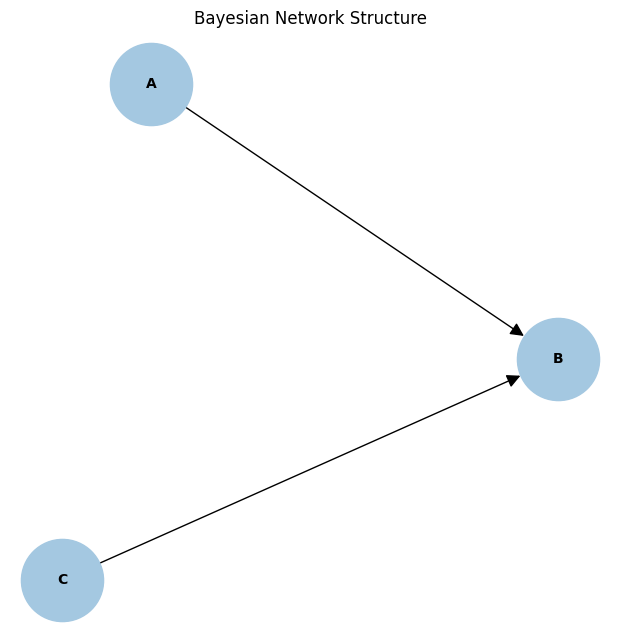

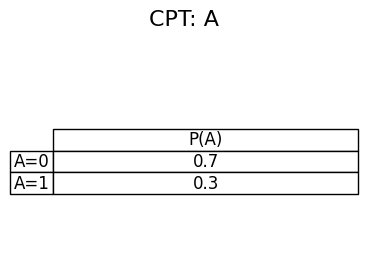

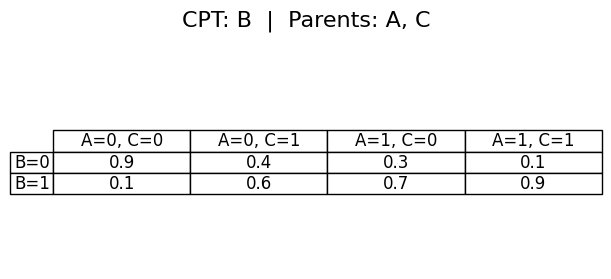

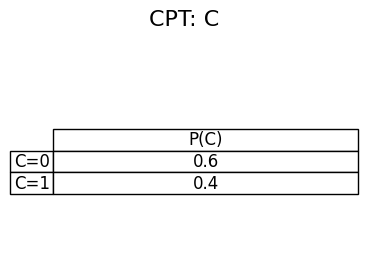

In [2]:
# Nodes
A = Node("A", [0, 1])
C = Node("C", [0, 1])
B = Node("B", [0, 1])

B.set_parents([A, C])

A.set_cpt([0.7, 0.3])
C.set_cpt([0.6, 0.4])
B.set_cpt([
    [[0.9, 0.4], [0.3, 0.1]], # P(B=0|A,C)
    [[0.1, 0.6], [0.7, 0.9]]  # P(B=1|A,C)
])

bn = BayesNet([A, B, C])

vis.plot_bayes_net(bn)
vis.plot_all_cpt_tables(bn)

In [3]:
from utils.bayes_net import BayesNet, Node

def make_power_plant_net():
    # Nodes (Boolean domain: 0=False, 1=True)
    T  = Node("T",  [0, 1])   # actual temperature (1=hot)
    FG = Node("F_G",[0, 1])   # gauge faulty (1=faulty)
    G  = Node("G",  [0, 1])   # gauge reading (1=high)
    FA = Node("F_A",[0, 1])   # alarm faulty (1=faulty)
    A  = Node("A",  [0, 1])   # alarm sounds (1=sounds)

    # Parent structure
    FG.set_parents([T])       # T -> F_G
    G.set_parents([T, FG])    # T, F_G -> G
    A.set_parents([G, FA])    # G, F_A -> A

    bn = BayesNet([T, FG, G, FA, A])
    return bn


def set_probability(bn):
    # Helper: fetch nodes by name (robust to node ordering)
    nodes = {n.name: n for n in bn.nodes}
    T  = nodes["T"]
    FG = nodes["F_G"]
    G  = nodes["G"]
    FA = nodes["F_A"]
    A  = nodes["A"]

    # 3) P(T=hot)=0.2
    # Node.set_cpt expects [P(value=0), P(value=1)]
    T.set_cpt([0.8, 0.2])

    # 2) P(F_A=faulty)=0.15
    FA.set_cpt([0.85, 0.15])

    # 4) P(F_G=faulty | T): if T=1 => 0.8 else 0.05
    # Parents: [T] with ordering T=0 then T=1
    # CPT format for 1 parent:
    #   [ [P(FG=0|T=0), P(FG=0|T=1)],
    #     [P(FG=1|T=0), P(FG=1|T=1)] ]
    FG.set_cpt([
        [0.95, 0.20],  # FG=0 (not faulty)
        [0.05, 0.80],  # FG=1 (faulty)
    ])

    # 1) Gauge reading correctness:
    # If FG=0: correct w.p. 0.95
    # If FG=1: correct w.p. 0.20
    #
    # Parents for G: [T, FG] with ordering T (rows: 0,1) and FG (cols: 0,1)
    # We need P(G=1|T,FG) table:
    #   T=0: FG=0 -> 0.05, FG=1 -> 0.80
    #   T=1: FG=0 -> 0.95, FG=1 -> 0.20
    pG1 = [
        [0.05, 0.80],  # T=0
        [0.95, 0.20],  # T=1
    ]
    pG0 = [
        [1 - pG1[0][0], 1 - pG1[0][1]],
        [1 - pG1[1][0], 1 - pG1[1][1]],
    ]
    G.set_cpt([
        pG0,  # P(G=0|T,FG)
        pG1,  # P(G=1|T,FG)
    ])

    # 5) Alarm responds correctly to gauge:
    # If FA=0: correct w.p. 0.90  => A=G with prob 0.90
    # If FA=1: correct w.p. 0.55  => A=G with prob 0.55
    #
    # Parents for A: [G, FA] with ordering G (rows:0,1) and FA (cols:0,1)
    # P(A=1|G,FA):
    #   G=0: FA=0 -> 0.10, FA=1 -> 0.45
    #   G=1: FA=0 -> 0.90, FA=1 -> 0.55
    pA1 = [
        [0.10, 0.45],  # G=0
        [0.90, 0.55],  # G=1
    ]
    pA0 = [
        [1 - pA1[0][0], 1 - pA1[0][1]],
        [1 - pA1[1][0], 1 - pA1[1][1]],
    ]
    A.set_cpt([
        pA0,  # P(A=0|G,FA)
        pA1,  # P(A=1|G,FA)
    ])

    return bn


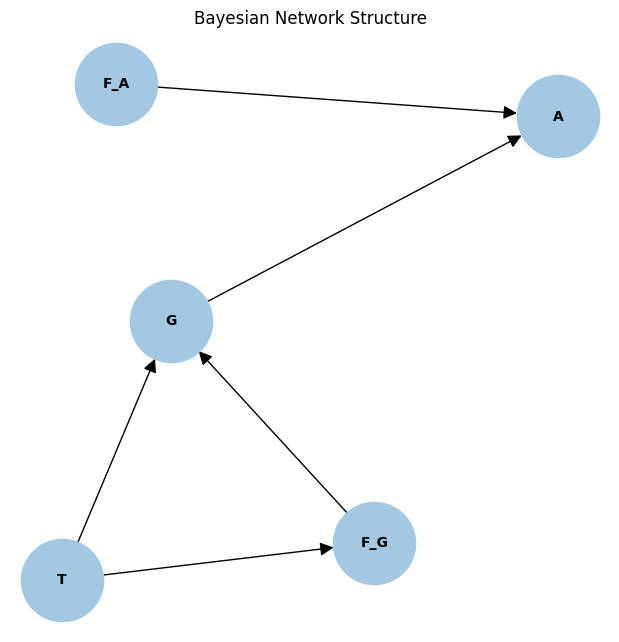

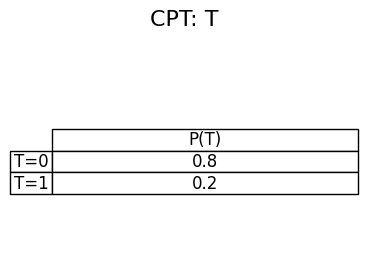

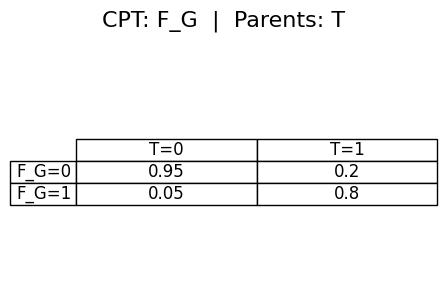

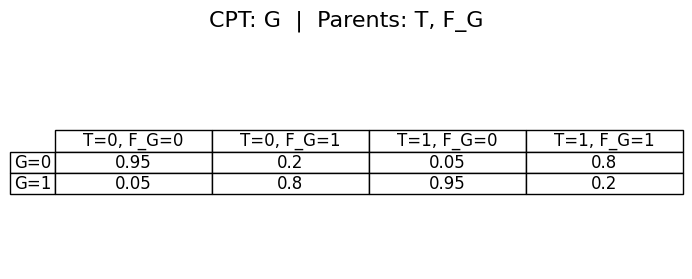

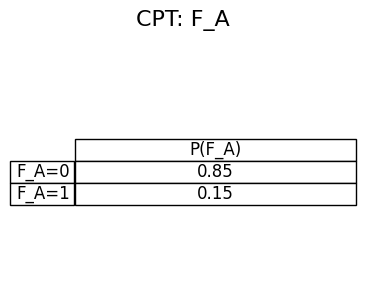

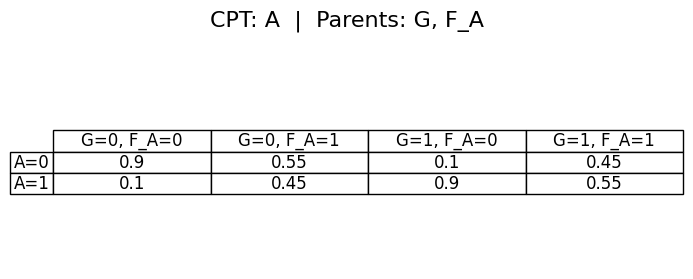

In [4]:
bn = make_power_plant_net()
bn = set_probability(bn)
vis.plot_bayes_net(bn)
vis.plot_all_cpt_tables(bn)


## Part 2: Exact Inference

In this part, you will compute probabilities using your Bayesian Network and exact methods.

You must implement:
- **Inference by Enumeration**
- **Inference by Variable Elimination**

You will also need **joint probability computation** when required so you must implement that too.

---

### Required Queries

Using both inference methods, compute:

- **Marginal probability the alarm sounds**  
  P(A = True)

- **Marginal probability the gauge reads hot**  
  P(G = True)

- **Posterior probability that the temperature is hot given evidence**  
  P(T = True ∣ A=True, Fa=False, Fg=False)

---

### What You Must Implement

✔ A function to compute **joint probability** using the whole network  
✔ `enumeration_ask(query_var, evidence, bn)`  
✔ `variable_elimination(query_var, evidence, bn)`  

For each query, print:
- Probability result using Enumeration
- Probability result using Variable Elimination
- Compare → Confirm that both methods match


In [5]:
def joint_probability(bn, assignment):
    prob = 1.0

    for node in bn.nodes:
        value = assignment[node.name]

        if not node.parents:
            # Root node
            prob *= node.cpt[value]
        else:
            # Build index into CPT
            parent_values = tuple(
                assignment[parent.name] for parent in node.parents
            )

            prob *= node.cpt[value][parent_values]

    return prob


import itertools

def all_assignments(variables):
    for values in itertools.product([0,1], repeat=len(variables)):
        yield dict(zip(variables, values))


def enumeration_ask(query_var, evidence, bn):
    Q = {0: 0.0, 1: 0.0}

    hidden_vars = [
        node.name for node in bn.nodes
        if node.name != query_var and node.name not in evidence
    ]

    for q_value in [0, 1]:
        extended_evidence = dict(evidence)
        extended_evidence[query_var] = q_value

        total = 0.0
        for assignment in all_assignments(hidden_vars):
            full_assignment = dict(extended_evidence)
            full_assignment.update(assignment)

            total += joint_probability(bn, full_assignment)

        Q[q_value] = total

    # Normalize
    norm = Q[0] + Q[1]
    Q[0] /= norm
    Q[1] /= norm

    return Q

class Factor:
    def __init__(self, variables, table):
        self.variables = variables  # list of variable names
        self.table = table          # dict {assignment_tuple: value}

def make_factor(node, evidence):
    variables = [node.name] + [p.name for p in node.parents]
    table = {}

    for assignment in all_assignments(variables):
        if any(
            var in evidence and assignment[var] != evidence[var]
            for var in variables
        ):
            continue

        val = assignment[node.name]
        if not node.parents:
            prob = node.cpt[val]
        else:
            parent_vals = tuple(assignment[p.name] for p in node.parents)
            prob = node.cpt[val][parent_vals]

        table[tuple(assignment[v] for v in variables)] = prob

    return Factor(variables, table)

def multiply_factors(f1, f2):
    vars_new = list(dict.fromkeys(f1.variables + f2.variables))
    table = {}

    for a1, p1 in f1.table.items():
        d1 = dict(zip(f1.variables, a1))
        for a2, p2 in f2.table.items():
            d2 = dict(zip(f2.variables, a2))

            if any(v in d1 and v in d2 and d1[v] != d2[v] for v in d1):
                continue

            merged = {**d1, **d2}
            key = tuple(merged[v] for v in vars_new)
            table[key] = table.get(key, 0) + p1 * p2

    return Factor(vars_new, table)

def sum_out(var, factor):
    vars_new = [v for v in factor.variables if v != var]
    table = {}

    for assignment, prob in factor.table.items():
        d = dict(zip(factor.variables, assignment))
        key = tuple(d[v] for v in vars_new)
        table[key] = table.get(key, 0) + prob

    return Factor(vars_new, table)


def variable_elimination(query_var, evidence, bn):
    # Initial factors
    factors = [make_factor(node, evidence) for node in bn.nodes]

    hidden_vars = [
        node.name for node in bn.nodes
        if node.name != query_var and node.name not in evidence
    ]

    for var in hidden_vars:
        related = [f for f in factors if var in f.variables]
        factors = [f for f in factors if var not in f.variables]

        product = related[0]
        for f in related[1:]:
            product = multiply_factors(product, f)

        factors.append(sum_out(var, product))

    # Multiply remaining factors
    result = factors[0]
    for f in factors[1:]:
        result = multiply_factors(result, f)

    # Extract distribution
    Q = {0: 0.0, 1: 0.0}
    idx = result.variables.index(query_var)

    for assignment, prob in result.table.items():
        Q[assignment[idx]] += prob

    # Normalize
    norm = Q[0] + Q[1]
    Q[0] /= norm
    Q[1] /= norm

    return Q



In [6]:
def enumeration_prob(query_var, value, evidence, bn):
    """
    Returns P(query_var=value | evidence) using enumeration.
    value: 0 or 1 (or whatever is in node.values)
    """
    dist = enumeration_ask(query_var, evidence, bn)
    return dist[value]


def variable_elimination_prob(query_var, value, evidence, bn):
    """
    Returns P(query_var=value | evidence) using variable elimination.
    value: 0 or 1 (or whatever is in node.values)
    """
    dist = variable_elimination(query_var, evidence, bn)
    return dist[value]

In [8]:
queries = [
    ("A", 1, {}, "P(alarm=True)"),
    ("G", 1, {}, "P(gauge=True)"),
    ("T", 1, {"A": 1, "F_A": 0, "F_G": 0},
     "P(temperature=True | alarm=True, faulty alarm=False, faulty gauge=False)")
]


for q_var, target, ev, label in queries:
    print(f"\n--- {label} ---")
    enum_res = enumeration_prob(q_var, target, ev, bn)
    ve_res = variable_elimination_prob(q_var, target, ev, bn)
    print(f"Enumeration : {enum_res:.3f}")
    print(f"Var. Elim.  : {ve_res:.3f}")



--- P(alarm=True) ---
Enumeration : 0.250
Var. Elim.  : 0.250

--- P(gauge=True) ---
Enumeration : 0.140
Var. Elim.  : 0.140

--- P(temperature=True | alarm=True, faulty alarm=False, faulty gauge=False) ---
Enumeration : 0.244
Var. Elim.  : 0.244


## Part 3: Approximate Inference

Consider the following scenario: 

There are five frisbee teams (T1, T2, T3,...,T5). A match is played between teams Ti and Ti+1 to give a total of 5 matches, i.e. T1vsT2, T2vsT3, ..., T4vsT5, T5vsT1.

Each team can either win, lose, or draw in a match. Each team has a fixed but unknown skill level, represented as an integer from 0 to 3. Each match's outcome is probabilistically proportional to the difference in skill level between the teams.

We want to estimate the outcome of the last match (T5vsT1), given prior knowledge of other 4 matches. Rather than using inference, we will do so by sampling the network using three models: Rejection Sampling, Likelihood Weighting, and Gibbs Sampling.

First, work on a similar, smaller network! With just 3 teams. 

### 3.1) Build a smaller network with 3 teams

For the first sub-part, consider a smaller network with 3 teams : the Airheads, the Buffoons, and the Clods (A, B and C for short). 3 total matches are played. 
Build a Bayes Net to represent the three teams and their influences on the match outcomes. Assume the following variable conventions:

| variable name | description|
|---------|:------:|
|A| A's skill level|
|B | B's skill level|
|C | C's skill level|
|AvB | the outcome of A vs. B <br> (0 = A wins, 1 = B wins, 2 = tie)|
|BvC | the outcome of B vs. C <br> (0 = B wins, 1 = C wins, 2 = tie)|
|CvA | the outcome of C vs. A <br> (0 = C wins, 1 = A wins, 2 = tie)|

Assume that each team has the following prior distribution of skill levels:

|skill level|P(skill level)|
|----|:----:|
|0|0.15|
|1|0.45|
|2|0.30|
|3|0.10|

In addition, assume that the differences in skill levels correspond to the following probabilities of winning:

| skill difference <br> (T2 - T1) | T1 wins | T2 wins| Tie |
|------------|----------|---|:--------:|
|0|0.10|0.10|0.80|
|1|0.20|0.60|0.20|
|2|0.15|0.75|0.10|
|3|0.05|0.90|0.05|

In [9]:
from utils.bayes_net import BayesNet, Node

def make_game_network():
    # Skill nodes (0,1,2,3)
    A = Node("A", [0, 1, 2, 3])
    B = Node("B", [0, 1, 2, 3])
    C = Node("C", [0, 1, 2, 3])

    # Match outcome nodes (0=first wins, 1=second wins, 2=tie)
    AvB = Node("AvB", [0, 1, 2])
    BvC = Node("BvC", [0, 1, 2])
    CvA = Node("CvA", [0, 1, 2])

    # Parent relationships
    AvB.set_parents([A, B])
    BvC.set_parents([B, C])
    CvA.set_parents([C, A])

    bn = BayesNet([A, B, C, AvB, BvC, CvA])
    return bn

skill_prior = [0.15, 0.45, 0.30, 0.10]

def set_probability(bn):
    nodes = {n.name: n for n in bn.nodes}

    A, B, C = nodes["A"], nodes["B"], nodes["C"]
    AvB, BvC, CvA = nodes["AvB"], nodes["BvC"], nodes["CvA"]

    # Skill priors
    A.set_cpt([0.15, 0.45, 0.30, 0.10])
    B.set_cpt([0.15, 0.45, 0.30, 0.10])
    C.set_cpt([0.15, 0.45, 0.30, 0.10])

    # Outcome probabilities based on skill difference
    diff_table = {
        0: [0.10, 0.10, 0.80],
        1: [0.20, 0.60, 0.20],
        2: [0.15, 0.75, 0.10],
        3: [0.05, 0.90, 0.05],
    }

    def build_match_cpt(team1, team2):
        cpt = [[], [], []]  # outcomes 0,1,2
        for s1 in team1.values:
            row = [[], [], []]
            for s2 in team2.values:
                diff = abs(s2 - s1)
                probs = diff_table[diff]
                row[0].append(probs[0])
                row[1].append(probs[1])
                row[2].append(probs[2])
            for i in range(3):
                cpt[i].append(row[i])
        return cpt

    AvB.set_cpt(build_match_cpt(A, B))
    BvC.set_cpt(build_match_cpt(B, C))
    CvA.set_cpt(build_match_cpt(C, A))

    return bn


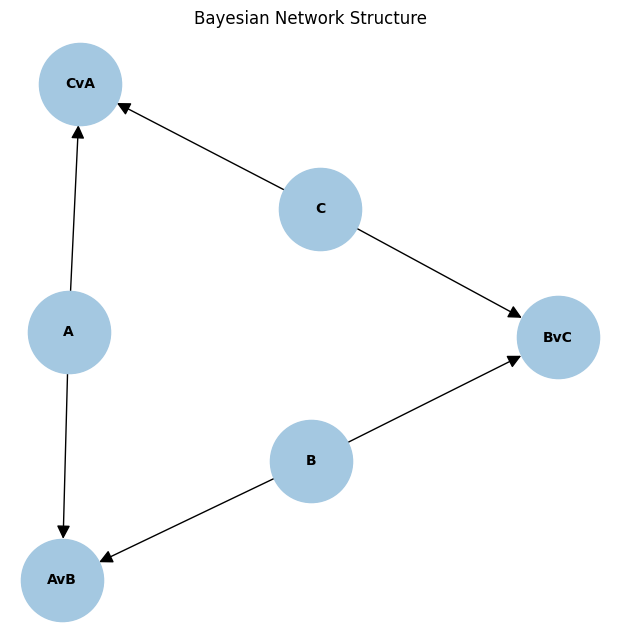

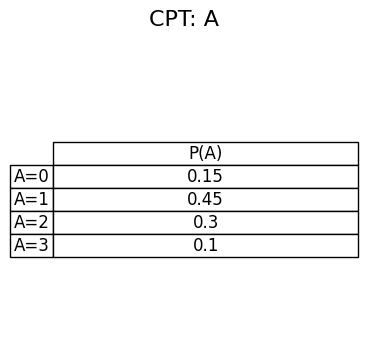

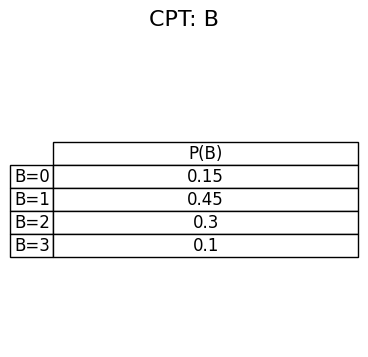

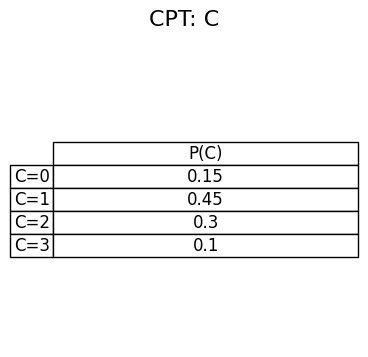

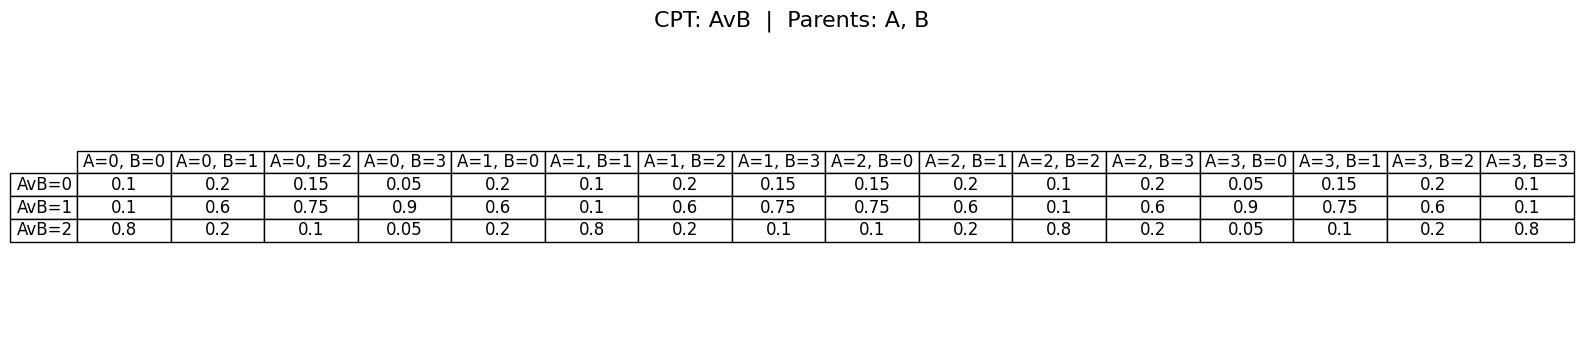

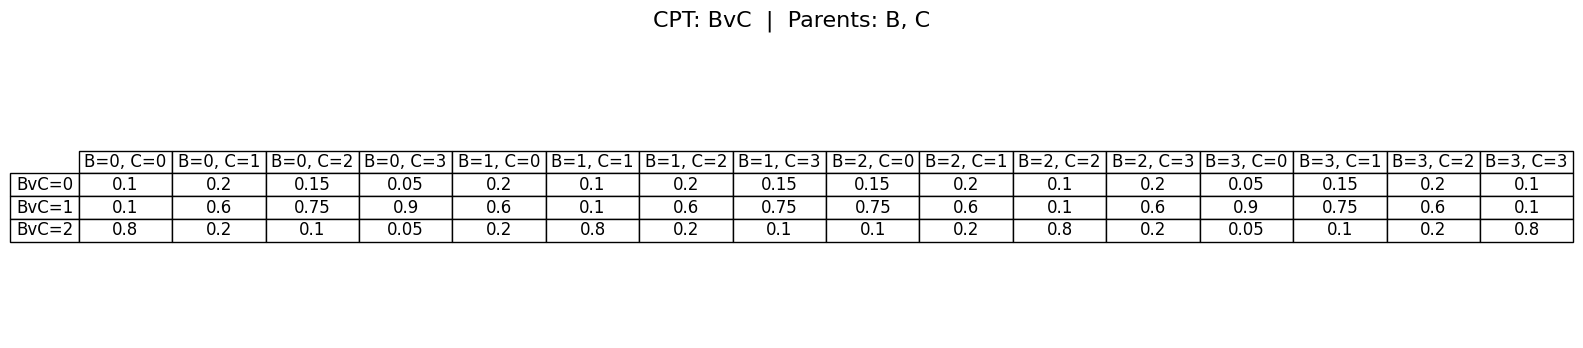

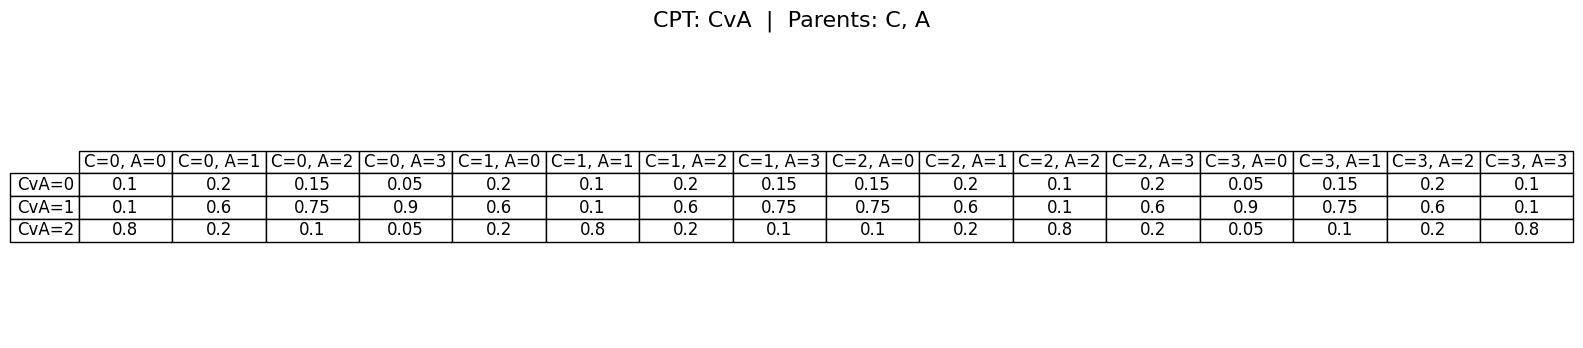

In [10]:
bn = make_game_network()
bn = set_probability(bn)
vis.plot_bayes_net(bn)
vis.plot_all_cpt_tables(bn)


### 3.2) Calculate posterior distribution for the 3rd match.

Suppose that you know the following outcome of two of the three games: A beats B and B draws with C. Start by calculating the posterior distribution for the outcome of the CvA match in calculate_posterior(). Use Enumeration ONLY. 

In [11]:
def calculate_posterior(bn):
    """
    Returns posterior distribution over CvA given:
    AvB = 0 (A beats B)
    BvC = 2 (B draws with C)

    Output format:
    {0: P(C wins), 1: P(A wins), 2: P(tie)}
    """

    evidence = {
        "AvB": 0,
        "BvC": 2
    }

    posterior = {0: 0.0, 1: 0.0, 2: 0.0}

    # Hidden variables: A, B, C
    hidden_vars = ["A", "B", "C"]

    import itertools

    for cva_outcome in [0, 1, 2]:
        total = 0.0

        for a, b, c in itertools.product([0,1,2,3], repeat=3):
            assignment = {
                "A": a,
                "B": b,
                "C": c,
                "AvB": 0,
                "BvC": 2,
                "CvA": cva_outcome
            }

            total += joint_probability(bn, assignment)

        posterior[cva_outcome] = total

    # Normalize
    norm = sum(posterior.values())
    for k in posterior:
        posterior[k] /= norm

    return posterior


In [12]:
posterior = calculate_posterior(bn)
posterior

{0: 0.16141938297176492, 1: 0.48171263490679167, 2: 0.3568679821214434}

### 3.3) Rejection Sampling

Now suppose you have 5 teams. You don't necessarily need to create a new network. You can just use the probability distributions tables from the previous part. Although be careful while indexing them.

Use **Rejection Sampling** to estimate the posterior probability of the 5th match (T5vT1). The algorithm works as follows:

1. Sample a full state (skills + matches) from the prior distribution.
2. Reject the sample if it is inconsistent with the evidence (the 4 known matches).
3. Keep track of how often each outcome occurs for the 5th match.
4. Normalize counts to get estimated probabilities.

Implement this in the function `rejection_sampling()`.


In [13]:
import random

def rejection_sampling(bayes_net, query_index, evidence, num_samples=10000, number_of_teams=5):
    """
    Rejection Sampling 

    Indexing assumption:
      - 0..number_of_teams-1 : team skills
      - number_of_teams..number_of_teams+number_of_teams-1 : match outcomes
        match i (0-based) is between team i and team (i+1)%n
        outcome encoding: 0 = first team wins, 1 = second team wins, 2 = tie
    """

    # Prior over skills (0..3)
    skill_prior = [0.15, 0.45, 0.30, 0.10]

    # Outcome probabilities when (T2 - T1) = +k, k in {0,1,2,3}
    # Format: [P(T1 wins), P(T2 wins), P(tie)]
    diff_table = {
        0: [0.10, 0.10, 0.80],
        1: [0.20, 0.60, 0.20],
        2: [0.15, 0.75, 0.10],
        3: [0.05, 0.90, 0.05],
    }

    def categorical_sample(probs):
        r = random.random()
        cum = 0.0
        for i, p in enumerate(probs):
            cum += p
            if r <= cum:
                return i
        return len(probs) - 1  # numerical safety

    def sample_skill():
        return categorical_sample(skill_prior)

    def outcome_probs(skill_team1, skill_team2):
        d = skill_team2 - skill_team1
        k = abs(d)
        base = diff_table[k]  # probs when team2 is k stronger than team1 (or equal if k=0)
        if d >= 0:
            # team2 is stronger or equal -> base applies directly
            return base
        else:
            # team1 is stronger by k -> swap win probs
            return [base[1], base[0], base[2]]

    posterior_counts = [0, 0, 0]  # for query outcome 0/1/2
    accepted = 0

    n = number_of_teams
    match_start = n
    match_end = n + n  # n matches in the cycle

    for _ in range(num_samples):
        # 1) Sample skills
        skills = [sample_skill() for _ in range(n)]

        # 2) Sample all matches given skills
        matches = []
        for i in range(n):
            team1 = i
            team2 = (i + 1) % n
            probs = outcome_probs(skills[team1], skills[team2])
            matches.append(categorical_sample(probs))

        # Build full sample assignment by index
        sample = {}
        for i in range(n):
            sample[i] = skills[i]
        for i in range(n):
            sample[match_start + i] = matches[i]

        # 3) Reject if inconsistent with evidence
        ok = True
        for ev_idx, ev_val in evidence.items():
            if sample.get(ev_idx, None) != ev_val:
                ok = False
                break
        if not ok:
            continue

        accepted += 1
        q_val = sample[query_index]
        posterior_counts[q_val] += 1

    # 4) Normalize
    posterior = [0.0, 0.0, 0.0]
    if accepted > 0:
        posterior = [c / accepted for c in posterior_counts]
    else:
        posterior = [0.0, 0.0, 0.0]

    return posterior


### 3.4) Likelihood Weighting

Next, use **Likelihood Weighting** to estimate the posterior probability of the 5th match (T5vT1). 

The algorithm works as follows:

1. Sample only the non-evidence variables from their conditional distributions.
2. Assign a weight to the sample based on the probability of the evidence given the sampled values.
3. Aggregate the weighted counts for the query variable.
4. Normalize the weighted counts to get estimated probabilities.

Implement this in the function `likelihood_weighting()`.


In [14]:
import random

def likelihood_weighting(bayes_net, query_index, evidence, num_samples=10000, number_of_teams=5):
    """
    Likelihood Weighting for the cyclic league model.

    Indexing assumption:
      - 0..n-1 : team skills
      - n..2n-1 : match outcomes, match i is between team i and (i+1)%n
      - outcome encoding: 0=first wins, 1=second wins, 2=tie
    """

    # Prior over skills (0..3)
    skill_prior = [0.15, 0.45, 0.30, 0.10]

    # Base table for diff = (T2 - T1) >= 0, format: [P(T1 wins), P(T2 wins), P(tie)]
    diff_table = {
        0: [0.10, 0.10, 0.80],
        1: [0.20, 0.60, 0.20],
        2: [0.15, 0.75, 0.10],
        3: [0.05, 0.90, 0.05],
    }

    def categorical_sample(probs):
        r = random.random()
        cum = 0.0
        for i, p in enumerate(probs):
            cum += p
            if r <= cum:
                return i
        return len(probs) - 1

    def sample_skill():
        return categorical_sample(skill_prior)

    def outcome_probs(skill_team1, skill_team2):
        d = skill_team2 - skill_team1
        k = abs(d)
        base = diff_table[k]
        if d >= 0:
            return base
        else:
            # team1 stronger -> swap win probs
            return [base[1], base[0], base[2]]

    n = number_of_teams
    match_start = n

    weighted_counts = [0.0, 0.0, 0.0]

    for _ in range(num_samples):
        # 1) sample non-evidence variables: skills (always non-evidence here)
        skills = [sample_skill() for _ in range(n)]

        # 2) compute weight from evidence matches
        w = 1.0
        for ev_idx, ev_val in evidence.items():
            # evidence indices should refer to matches (n..2n-1)
            match_i = ev_idx - match_start
            team1 = match_i
            team2 = (match_i + 1) % n
            probs = outcome_probs(skills[team1], skills[team2])
            w *= probs[ev_val]

        # 3) sample query match outcome (unless query itself is evidence)
        q_match_i = query_index - match_start
        q_team1 = q_match_i
        q_team2 = (q_match_i + 1) % n
        q_probs = outcome_probs(skills[q_team1], skills[q_team2])

        if query_index in evidence:
            q_val = evidence[query_index]
            # (optional) you could multiply weight by P(query evidence | skills)
            # but typically query is not in evidence for this task
        else:
            q_val = categorical_sample(q_probs)

        # 4) aggregate weighted counts
        weighted_counts[q_val] += w

    # Normalize weighted counts
    total = sum(weighted_counts)
    if total == 0.0:
        return [0.0, 0.0, 0.0]
    return [c / total for c in weighted_counts]


### 3.5) Gibbs Sampling

Next, use **Gibbs Sampling** to estimate the posterior probability of a variable (e.g., the 5th match, T5vT1).

The algorithm works as follows:

1. Initialize the state: Assign random values to all non-evidence variables; fix evidence variables to their known values.
2. Iteratively update variables: At each step, pick one non-evidence variable and sample a new value conditioned on its Markov blanket (its parents, children, and children's other parents).
3. Track the query variable: Record the value of the query variable at each iteration.
4. Repeat for many iterations: Continue updating variables to allow the chain to approach the stationary distribution.
5. Normalize the counts: After all iterations (optionally discarding an initial burn-in period), normalize the counts of the query variable’s values to estimate posterior probabilities.

Implement this in the function `gibbs_sampling()`.

In [15]:
import random

def gibbs_sampling(bayes_net, query_index, evidence, num_samples=10000, number_of_teams=5):
    """
    Gibbs sampling (skills-only) to estimate posterior of a match outcome.

    Indexing assumption:
      - 0..n-1 : team skills (values 0..3)
      - n..2n-1 : match outcomes (values 0..2),
        match i is between team i and (i+1)%n, outcome:
          0 = first team wins, 1 = second team wins, 2 = tie
    Evidence is given over match indices (typically 4 known matches).
    """

    # Priors
    skill_prior = [0.15, 0.45, 0.30, 0.10]

    diff_table = {
        0: [0.10, 0.10, 0.80],
        1: [0.20, 0.60, 0.20],
        2: [0.15, 0.75, 0.10],
        3: [0.05, 0.90, 0.05],
    }

    def categorical_sample(probs):
        r = random.random()
        cum = 0.0
        for i, p in enumerate(probs):
            cum += p
            if r <= cum:
                return i
        return len(probs) - 1

    def outcome_probs(skill_team1, skill_team2):
        d = skill_team2 - skill_team1
        k = abs(d)
        base = diff_table[k]
        if d >= 0:
            return base
        else:
            return [base[1], base[0], base[2]]

    n = number_of_teams
    match_start = n

    # Map match index -> (team1, team2)
    def match_teams(match_i):
        t1 = match_i
        t2 = (match_i + 1) % n
        return t1, t2

    # For each team, list the match indices it participates in (two matches in cycle)
    team_to_matches = [[] for _ in range(n)]
    for mi in range(n):
        t1, t2 = match_teams(mi)
        team_to_matches[t1].append(mi)
        team_to_matches[t2].append(mi)

    # -------- 1) Initialize state: random skills; evidence matches fixed externally --------
    skills = [categorical_sample(skill_prior) for _ in range(n)]

    # Burn-in (optional but recommended)
    burn_in = max(1000, num_samples // 10)

    # Track query match outcomes
    counts = [0, 0, 0]

    # Precompute which skill variables are non-evidence (all skills are non-evidence here)
    skill_indices = list(range(n))

    # -------- 2) Gibbs iterations --------
    total_iters = burn_in + num_samples
    for it in range(total_iters):
        # Update one skill variable at a time (can be random-scan or systematic)
        i = random.choice(skill_indices)

        # Compute unnormalized distribution over s_i in {0,1,2,3}
        probs_si = []
        for si in [0, 1, 2, 3]:
            # prior term P(S_i=si)
            p = skill_prior[si]

            # likelihood terms from evidence matches involving team i
            # evidence is on match outcomes; each such match contributes P(M=ev | skills)
            for mi in team_to_matches[i]:
                match_idx = match_start + mi
                if match_idx not in evidence:
                    continue  # only evidence contributes to conditioning here

                ev_outcome = evidence[match_idx]
                t1, t2 = match_teams(mi)

                s1 = skills[t1] if t1 != i else si
                s2 = skills[t2] if t2 != i else si

                p_match = outcome_probs(s1, s2)[ev_outcome]
                p *= p_match

            probs_si.append(p)

        # Normalize and sample new skill value
        Z = sum(probs_si)
        if Z == 0:
            # Degenerate (should be very rare): fall back to prior
            skills[i] = categorical_sample(skill_prior)
        else:
            probs_si = [p / Z for p in probs_si]
            skills[i] = categorical_sample(probs_si)

        # -------- 3) After burn-in, sample/query the query match outcome --------
        if it >= burn_in:
            q_match_i = query_index - match_start
            q_t1, q_t2 = match_teams(q_match_i)

            q_probs = outcome_probs(skills[q_t1], skills[q_t2])

            # If query itself is evidence, just count that fixed value; else sample from conditional
            if query_index in evidence:
                q_val = evidence[query_index]
            else:
                q_val = categorical_sample(q_probs)

            counts[q_val] += 1

    # -------- 4) Normalize counts --------
    total = sum(counts)
    if total == 0:
        return [0.0, 0.0, 0.0]
    return [c / total for c in counts]


### 3.6) Compare Methods

Now that you have implemented sampling methods, you need to compare the prediction of these methods (approximate) with enumeration method (exact). First predict posterior probabilities for last match in a competetion of 3 teams with the same evidence as part 3.2 and then compare sampling results with enumeration.

After that predict posterior probabilities for last match in a competetion of 5 teams with the given evidence and show the difference between these methods.

Also test your sampling methods for other given evidence or number of teams and provide reason why your results correspond to the given evidence.

In [18]:
bn_3 = make_game_network()
bn_3 = set_probability(bn_3)


In [19]:
# TODO: Compare approximate and exact methods for inference in 3 team version
def normalize_list(x):
    s = sum(x)
    return [v / s for v in x] if s > 0 else [0.0 for _ in x]

def l1_distance(p, q):
    return sum(abs(a - b) for a, b in zip(p, q))

# --- TODO 1: Compare approximate and exact methods for inference in 3 team version ---

# Evidence from Part 3.2:
# A beats B  => AvB = 0
# B draws C  => BvC = 2
evidence_3 = {3: 0, 4: 2}   # match indices for n=3: AvB=3, BvC=4
query_index_3 = 5           # CvA match index for n=3

# Exact posterior using Enumeration (from your Part 3.2 function)
exact_dict = calculate_posterior(bn_3)  # {0:..., 1:..., 2:...}
exact = normalize_list([exact_dict[0], exact_dict[1], exact_dict[2]])

# Approximate posteriors (sampling)
num_samples = 50000
rs = normalize_list(rejection_sampling(None, query_index_3, evidence_3, num_samples=num_samples, number_of_teams=3))
lw = normalize_list(likelihood_weighting(None, query_index_3, evidence_3, num_samples=num_samples, number_of_teams=3))
gb = normalize_list(gibbs_sampling(None, query_index_3, evidence_3, num_samples=num_samples, number_of_teams=3))

# Print comparison
print("3-TEAM Comparison (Query=CvA | Evidence: AvB=0, BvC=2)")
print("Outcome meanings for CvA: 0=C wins, 1=A wins, 2=tie\n")

print(f"Exact (Enumeration):      {exact}")
print(f"Rejection Sampling:       {rs}   | L1={l1_distance(exact, rs):.4f}")
print(f"Likelihood Weighting:     {lw}   | L1={l1_distance(exact, lw):.4f}")
print(f"Gibbs Sampling:           {gb}   | L1={l1_distance(exact, gb):.4f}")


3-TEAM Comparison (Query=CvA | Evidence: AvB=0, BvC=2)
Outcome meanings for CvA: 0=C wins, 1=A wins, 2=tie

Exact (Enumeration):      [0.16141938297176492, 0.48171263490679167, 0.3568679821214434]
Rejection Sampling:       [0.24184829991281603, 0.4591107236268527, 0.2990409764603313]   | L1=0.1609
Likelihood Weighting:     [0.2482874882610933, 0.4556297656041826, 0.2960827461347241]   | L1=0.1737
Gibbs Sampling:           [0.24672, 0.45822, 0.29506]   | L1=0.1706


In [20]:
# TODO: Compare approximate methods for inference in 5 team version

def normalize_list(x):
    s = sum(x)
    return [v / s for v in x] if s > 0 else [0.0 for _ in x]

def l1_distance(p, q):
    return sum(abs(a - b) for a, b in zip(p, q))

# -------------------------
# Evidence (chosen scenario)
# -------------------------
# n = 5
# matches: 5..9
# 5: T1vT2, 6: T2vT3, 7: T3vT4, 8: T4vT5, 9: T5vT1 (query)
# outcome: 0=first wins, 1=second wins, 2=tie

evidence_5 = {
    5: 0,  # T1 beats T2
    6: 2,  # T2 draws T3
    7: 0,  # T3 beats T4
    8: 0,  # T4 beats T5
}

query_index_5 = 9  # T5vT1
num_samples = 100000  # higher for stability in 5-team case

# Run approximate inference methods
rs_5 = normalize_list(
    rejection_sampling(None, query_index_5, evidence_5,
                       num_samples=num_samples, number_of_teams=5)
)
lw_5 = normalize_list(
    likelihood_weighting(None, query_index_5, evidence_5,
                         num_samples=num_samples, number_of_teams=5)
)
gb_5 = normalize_list(
    gibbs_sampling(None, query_index_5, evidence_5,
                   num_samples=num_samples, number_of_teams=5)
)

# Print comparison
print("5-TEAM Comparison (Query=T5vT1)")
print("Evidence:")
print("  T1 beats T2")
print("  T2 draws T3")
print("  T3 beats T4")
print("  T4 beats T5\n")

print("Outcome meanings for T5vT1:")
print("  0 = T5 wins, 1 = T1 wins, 2 = tie\n")

print(f"Rejection Sampling:   {rs_5}")
print(f"Likelihood Weighting: {lw_5}")
print(f"Gibbs Sampling:       {gb_5}\n")

print(f"L1(RS, LW)    = {l1_distance(rs_5, lw_5):.4f}")
print(f"L1(RS, Gibbs) = {l1_distance(rs_5, gb_5):.4f}")
print(f"L1(LW, Gibbs) = {l1_distance(lw_5, gb_5):.4f}")


5-TEAM Comparison (Query=T5vT1)
Evidence:
  T1 beats T2
  T2 draws T3
  T3 beats T4
  T4 beats T5

Outcome meanings for T5vT1:
  0 = T5 wins, 1 = T1 wins, 2 = tie

Rejection Sampling:   [0.22641509433962265, 0.47924528301886793, 0.2943396226415094]
Likelihood Weighting: [0.22287489246311584, 0.4690372116162022, 0.30808789592068203]
Gibbs Sampling:       [0.22622, 0.462, 0.31178]

L1(RS, LW)    = 0.0275
L1(RS, Gibbs) = 0.0349
L1(LW, Gibbs) = 0.0141


In [21]:
# TODO: Test your sampling methods for other given evidence or number of teams

def normalize_list(x):
    s = sum(x)
    return [v / s for v in x] if s > 0 else [0.0 for _ in x]

def l1_distance(p, q):
    return sum(abs(a - b) for a, b in zip(p, q))

def match_explain(n, match_index, outcome):
    # match_index is in [n..2n-1]
    mi = match_index - n
    t1 = mi
    t2 = (mi + 1) % n
    if outcome == 0:
        return f"T{t1+1} beats T{t2+1}"
    elif outcome == 1:
        return f"T{t2+1} beats T{t1+1}"
    else:
        return f"T{t1+1} draws T{t2+1}"

def evidence_summary(n, evidence):
    lines = []
    for idx in sorted(evidence.keys()):
        lines.append(f"  M{idx-n+1}: {match_explain(n, idx, evidence[idx])}")
    return "\n".join(lines)

def query_outcome_meaning(n, query_index):
    mi = query_index - n
    t1 = mi
    t2 = (mi + 1) % n
    return f"Query is match M{mi+1} = T{t1+1} vs T{t2+1} | outcomes: 0=T{t1+1} wins, 1=T{t2+1} wins, 2=tie"

def run_all_samplers(n, query_index, evidence, num_samples=100000):
    rs = normalize_list(rejection_sampling(None, query_index, evidence, num_samples=num_samples, number_of_teams=n))
    lw = normalize_list(likelihood_weighting(None, query_index, evidence, num_samples=num_samples, number_of_teams=n))
    gb = normalize_list(gibbs_sampling(None, query_index, evidence, num_samples=num_samples, number_of_teams=n))
    return rs, lw, gb

def short_reason(n, evidence, query_index, posterior_like):
  
    # Heuristics
    outs = list(evidence.values())
    all_ties = all(v == 2 for v in outs)
    all_first_wins = all(v == 0 for v in outs)
    all_second_wins = all(v == 1 for v in outs)

    mi = query_index - n
    t1 = mi
    t2 = (mi + 1) % n

    if all_ties:
        return "Evidence is all ties → posterior favors closer skill levels, so tie probability tends to increase."
    if all_first_wins:
        return "Evidence shows a consistent pattern where the first team in each match wins → suggests a skill gradient along the cycle; outcomes favoring that implied ordering become more likely."
    if all_second_wins:
        return "Evidence shows the second team in each match wins → suggests the reverse skill gradient; query shifts accordingly."

    # Mixed evidence: use which outcome is highest as an interpretable reason
    best = max(range(3), key=lambda i: posterior_like[i])
    if best == 2:
        return "Mixed evidence does not strongly separate teams → posterior often assigns substantial mass to tie due to uncertainty in skill levels."
    if best == 0:
        return f"Evidence pattern makes it plausible that T{t1+1} is relatively strong (directly or transitively), increasing P(T{t1+1} wins)."
    return f"Evidence pattern makes it plausible that T{t2+1} is relatively strong (directly or transitively), increasing P(T{t2+1} wins)."


# -------------------------
# Define test cases
# -------------------------
# Each test case: (label, n_teams, evidence_dict, query_index, num_samples)

test_cases = []

# 5 teams: your previous “reasonable” evidence (baseline)
test_cases.append((
    "5 teams (baseline): T1>T2, T2~T3, T3>T4, T4>T5  | query=T5vT1",
    5,
    {5:0, 6:2, 7:0, 8:0},
    9,
    100000
))

# 5 teams: all ties
test_cases.append((
    "5 teams: all ties in observed matches  | query=T5vT1",
    5,
    {5:2, 6:2, 7:2, 8:2},
    9,
    120000
))

# 5 teams: all first teams win
test_cases.append((
    "5 teams: all first teams win (T1>T2, T2>T3, T3>T4, T4>T5) | query=T5vT1",
    5,
    {5:0, 6:0, 7:0, 8:0},
    9,
    120000
))

# 5 teams: all second teams win
test_cases.append((
    "5 teams: all second teams win (T2>T1, T3>T2, T4>T3, T5>T4) | query=T5vT1",
    5,
    {5:1, 6:1, 7:1, 8:1},
    9,
    120000
))

# 7 teams: mixed evidence (harder posterior)
# n=7, matches indices are 7..13, query last match is 13 (T7vT1)
test_cases.append((
    "7 teams: mixed evidence (more complex) | query=T7vT1",
    7,
    {7:0, 8:2, 9:1, 10:0, 11:2, 12:1},  # six observed matches
    13,
    150000
))


# -------------------------
# Run tests
# -------------------------
for label, n, ev, qidx, ns in test_cases:
    print("\n" + "="*len(label))
    print(label)
    print("="*len(label))
    print("Evidence:")
    print(evidence_summary(n, ev))
    print(query_outcome_meaning(n, qidx))

    rs, lw, gb = run_all_samplers(n, qidx, ev, num_samples=ns)

    print("\nPosteriors:")
    print(f"  Rejection Sampling   : {rs}")
    print(f"  Likelihood Weighting : {lw}")
    print(f"  Gibbs Sampling       : {gb}")

    print("\nDifferences (L1):")
    print(f"  L1(RS, LW)    = {l1_distance(rs, lw):.4f}")
    print(f"  L1(RS, Gibbs) = {l1_distance(rs, gb):.4f}")
    print(f"  L1(LW, Gibbs) = {l1_distance(lw, gb):.4f}")

    print("\nReason:")
    print(f"  {short_reason(n, ev, qidx, posterior_like=lw)}")



5 teams (baseline): T1>T2, T2~T3, T3>T4, T4>T5  | query=T5vT1
Evidence:
  M1: T1 beats T2
  M2: T2 draws T3
  M3: T3 beats T4
  M4: T4 beats T5
Query is match M5 = T5 vs T1 | outcomes: 0=T5 wins, 1=T1 wins, 2=tie

Posteriors:
  Rejection Sampling   : [0.218249075215783, 0.45745992601726265, 0.3242909987669544]
  Likelihood Weighting : [0.2193467082520934, 0.47208988761322845, 0.3085634041346781]
  Gibbs Sampling       : [0.2226, 0.46945, 0.30795]

Differences (L1):
  L1(RS, LW)    = 0.0315
  L1(RS, Gibbs) = 0.0327
  L1(LW, Gibbs) = 0.0065

Reason:
  Evidence pattern makes it plausible that T1 is relatively strong (directly or transitively), increasing P(T1 wins).

5 teams: all ties in observed matches  | query=T5vT1
Evidence:
  M1: T1 draws T2
  M2: T2 draws T3
  M3: T3 draws T4
  M4: T4 draws T5
Query is match M5 = T5 vs T1 | outcomes: 0=T5 wins, 1=T1 wins, 2=tie

Posteriors:
  Rejection Sampling   : [0.2530821917808219, 0.26404109589041097, 0.4828767123287671]
  Likelihood Weighting